# 2.5.4 Sáng không đều

**Mục tiêu:** áp dụng phương pháp xử lý ảnh cho đúng vấn đề này → train ResNet-18 **3 lần** → so sánh với baseline (không xử lý) → kết luận **cải thiện / không đổi / tệ đi** và **giải thích vì sao**.

**Cách đọc kết quả (quy tắc đặt trước khi chạy, giống mục 2.5.0 của báo cáo):**
- Mỗi cấu hình train **3 lần** (seed 42, 43, 44) để loại bỏ tính ngẫu nhiên của khởi tạo tham số, thứ tự lấy mẫu và flip.
- Δ = (cấu hình) − (baseline) **ghép cặp theo seed**, trung bình 3 seed. CI95: bootstrap 1 000 lần theo cụm `lesion_id`.
- **"CẢI THIỆN rõ" / "TỆ ĐI rõ"** chỉ khi đủ cả ba: |Δ| > std giữa 3 seed của baseline, CI95 không chứa 0, và cả 3 seed cùng dấu. Không đủ → **"không khác biệt rõ"**.
- Chọn cấu hình theo **val**; test chỉ để báo cáo. Không chọn seed hay ảnh "đẹp".

Chạy lần lượt từ trên xuống (Run All). Logic nằm trong `src/`; notebook chỉ gọi hàm và trình bày.

In [1]:
PROBLEM = "sang_khong_deu"
import os, sys
from pathlib import Path
if not Path("archive").exists() and Path("../archive").exists():
    os.chdir("..")                        # chạy từ thư mục gốc repo
sys.path.insert(0, str(Path.cwd()))
import pandas as pd
from IPython.display import display, Markdown
from src.report import notebook_utils as U
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 4)
P = U.PROBLEMS[PROBLEM]
NAMES = ["baseline"] + P["configs"]
print("Vấn đề:", P["name"], "| cấu hình so sánh:", NAMES)

Vấn đề: Sáng không đều | cấu hình so sánh: ['baseline', 'flat_L_s60', 'flat_L_s60_cond']


## 1. Vấn đề (từ EDA, mục 2.2)

- **Hiện tượng:** nền da tối dần về một góc hoặc về phía rìa, chuyển tiếp mềm (khác viền tối: chưa đen hẳn).
- **Đo bằng:** lưới 4×4, 12 ô viền, mỗi ô = trung vị mức xám của **da** (bỏ tổn thương bằng mask Otsu thô); chỉ số = ô sáng nhất − ô tối nhất. **Ngưỡng cờ:** > 38 mức xám (Q3 + 1,5·IQR), bỏ ảnh đã có viền tối → **247/10 015 ảnh (2,5%)**.
- **Liên hệ lỗi CNN (mục 2.8):** sau khi chuẩn hóa theo thành phần lớp, nhóm này có lỗi baseline **cao hơn kỳ vọng** ở cả test (+0,128) và val (+0,145) – vấn đề duy nhất có liên hệ nhất quán ở cả hai tập.

In [2]:
fl = pd.read_csv("outputs/eda/image_flags.csv")
sp = pd.concat([pd.read_csv(f"outputs/splits/{s}.csv")[["image_id"]].assign(split=s) for s in ("train_fit", "val", "test")])
d = sp.merge(fl[["image_id", "dx", P["flag"]]], on="image_id")
tab = d.groupby("split")[P["flag"]].agg(["sum", "size"]).rename(columns={"sum": "số ảnh bị cờ", "size": "tổng"})
tab["%"] = (tab["số ảnh bị cờ"] / tab["tổng"] * 100).round(1)
display(tab.loc[["train_fit", "val", "test"]])
display(d[d[P["flag"]] & (d.split == "test")].dx.value_counts().rename("thành phần lớp của nhóm cờ (test)").to_frame().T)

,số ảnh bị cờ,tổng,%
split,,,
train_fit,150,6408,2.3
val,45,1603,2.8
test,52,2004,2.6


dx,nv,mel,bkl,bcc,vasc,df
thành phần lớp của nhóm cờ (test),24,11,8,5,3,1


## 2. Áp dụng gì? (Ch.3 lọc không gian + Ch.4 hệ màu)

| Cấu hình | Áp cho | Các bước và tham số |
|---|---|---|
| `flat_L_s60` | **mọi ảnh** | chuyển sang CIE L\*a\*b\*, chỉ xử lý **L\*** (giữ màu a\*, b\*) → ước lượng **nền** B = lọc **Gauss** σ = 60 px chuẩn hóa chỉ trên **da** (bỏ tổn thương + viền đen) → **hiệu chỉnh nền** L' = L · trung vị(B) / B, hệ số kẹp trong [0,5; 2] |
| `flat_L_s60_cond` | **chỉ ảnh bị cờ "sáng không đều"** | như trên; ảnh khác giữ nguyên |

- **Lý do tham số:** σ = 60 px (≈ 1/8 cạnh dài 600) đủ lớn để nền không chứa chi tiết tổn thương, đủ nhỏ để theo được độ dốc sáng; chỉ ước lượng nền trên da để tổn thương tối lớn không bị coi là "nền tối" rồi bị làm sáng lên (mất tương phản); xử lý trên L\* vì màu là tín hiệu chẩn đoán.
- **Giả thuyết (viết trước khi train):**
  - **H1:** cân bằng nền giúp CNN so sánh tổn thương với da xung quanh nhất quán hơn → kỳ vọng cải thiện **trên nhóm sáng không đều**.
  - **H2:** bản áp **mọi ảnh** đổi nhẹ cả ảnh bình thường (ảnh nào cũng có chút chênh sáng) → hiệu ứng toàn tập nhỏ, có thể lệch khỏi phân phối ImageNet; bản **có điều kiện** chỉ đổi 2,5% ảnh nên tác động toàn tập rất nhỏ.

## 3. Ảnh trước / sau xử lý

Quy tắc chọn ảnh (cố định, không chọn ảnh "đẹp"): trong nhóm bị cờ ∩ `train_fit`, ảnh có chỉ số EDA gần **trung vị**, gần **phân vị 90** và **lớn nhất**. Bảng dưới: chỉ số EDA trước → sau, % ảnh còn vượt ngưỡng, % ảnh bị đổi và ΔE76 (mức đổi màu trung bình mỗi pixel) trên 100 ảnh bị cờ và 100 ảnh đối chứng (`train_fit`, rút ngẫu nhiên seed 42).

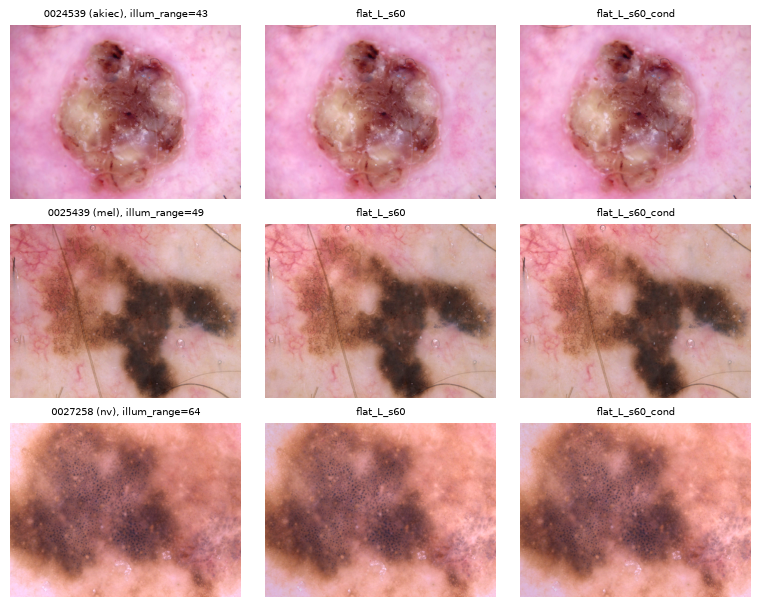

In [3]:
U.fig_before_after(PROBLEM, stem=f"{PROBLEM}_before_after");

In [4]:
display(U.image_effect(PROBLEM))

,cấu_hình,nhóm,n,illum_range trước (trung vị),illum_range sau (trung vị),% còn vượt ngưỡng,% ảnh bị đổi,ΔE76 TB
0,flat_L_s60,nhóm cờ,100,42.0,11.0,2.0,100.0,3.736
1,flat_L_s60,đối chứng,100,18.0,5.0,0.0,100.0,1.931
2,flat_L_s60_cond,nhóm cờ,100,42.0,11.0,2.0,100.0,3.736
3,flat_L_s60_cond,đối chứng,100,18.0,18.0,1.0,0.0,0.000


## 4. Áp dụng xử lý ảnh rồi train ResNet-18, 3 lần (seed 42, 43, 44)

- Giữ **đóng băng hoàn toàn** cấu hình của mục 2.4 (`FROZEN_CONFIG`: ResNet-18 `IMAGENET1K_V1`, 224×224, AdamW `lr=1e-4`, `wd=1e-4`, batch 32, 20 epoch, WRS, flip ngang/dọc, chọn epoch theo `val` macro-F1).
- Mọi cấu hình đọc từ lượt chạy thống nhất trên **NVIDIA L40S**, dùng chung chính xác một baseline với toàn bộ các mục 2.4–2.8 (không còn lệch giữa các máy).

In [5]:
# Seed nào đã có kết quả trong outputs/runs_cl/<cấu hình>/seed*/metrics.json thì được đọc lại, không train lại.
# Ctrl+C (hoặc Interrupt kernel) an toàn: chạy lại ô này sẽ tiếp tục từ seed còn thiếu.
for name in NAMES:
    U.train(name)
display(pd.Series(U.run_info(), name="cấu hình lần chạy").to_frame())

[03:15:42] [baseline seed 42] đã có metrics.json -> đọc lại


[03:15:42] [baseline seed 43] đã có metrics.json -> đọc lại


[03:15:42] [baseline seed 44] đã có metrics.json -> đọc lại


[03:15:42] [flat_L_s60 seed 42] đã có metrics.json -> đọc lại


[03:15:42] [flat_L_s60 seed 43] đã có metrics.json -> đọc lại


[03:15:42] [flat_L_s60 seed 44] đã có metrics.json -> đọc lại


[03:15:42] [flat_L_s60_cond seed 42] đã có metrics.json -> đọc lại


[03:15:42] [flat_L_s60_cond seed 43] đã có metrics.json -> đọc lại


[03:15:42] [flat_L_s60_cond seed 44] đã có metrics.json -> đọc lại


,cấu hình lần chạy
model,"resnet18 (torchvision, IMAGENET1K_V1), fc -> 7..."
batch_size,32
lr,0.0001
epochs,20
seeds,"[42, 43, 44]"
env,"{'torch': '2.13.0+cu126', 'gpu': 'NVIDIA L40S'}"
channels_last,False
eval_batch,32


## 5. So sánh với baseline

### 5.1 Toàn tập: bảng và biểu đồ cột theo từng lần chạy (3 seed)

In [6]:
T = U.comparison(NAMES, "test")
Tv = U.comparison(NAMES, "val")
cols = ["cấu hình", "macro_f1_mean", "macro_f1_std", "macro_f1_per_seed", "macro_f1_delta", "macro_f1_ci_lo",
        "macro_f1_ci_hi", "macro_f1_sign", "macro_f1_verdict", "balanced_acc_delta", "balanced_acc_sign", "balanced_acc_verdict"]
print("TEST (n = 2 004)"); display(T[[c for c in cols if c in T]])
print("VAL (n = 1 603) – tập dùng để chọn cấu hình"); display(Tv[[c for c in cols if c in Tv]])

TEST (n = 2 004)


,cấu hình,macro_f1_mean,macro_f1_std,macro_f1_per_seed,macro_f1_delta,macro_f1_ci_lo,macro_f1_ci_hi,macro_f1_sign,macro_f1_verdict,balanced_acc_delta,balanced_acc_sign,balanced_acc_verdict
0,baseline,0.6941,0.0160,0.6784; 0.6935; 0.7103,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,flat_L_s60,0.6686,0.0320,0.6832; 0.6320; 0.6908,-0.0254,-0.0503,0.0008,1+/2-,không khác biệt rõ,-0.0187,1+/2-,không khác biệt rõ
2,flat_L_s60_cond,0.6789,0.0035,0.6758; 0.6827; 0.6784,-0.0151,-0.0450,0.0108,0+/3-,không khác biệt rõ,-0.0153,0+/3-,không khác biệt rõ


VAL (n = 1 603) – tập dùng để chọn cấu hình


,cấu hình,macro_f1_mean,macro_f1_std,macro_f1_per_seed,macro_f1_delta,macro_f1_ci_lo,macro_f1_ci_hi,macro_f1_sign,macro_f1_verdict,balanced_acc_delta,balanced_acc_sign,balanced_acc_verdict
0,baseline,0.7254,0.0044,0.7248; 0.7213; 0.7301,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,flat_L_s60,0.7231,0.0081,0.7227; 0.7153; 0.7315,-0.0023,-0.0264,0.0188,1+/2-,không khác biệt rõ,0.0090,3+/0-,không khác biệt rõ
2,flat_L_s60_cond,0.7247,0.0019,0.7266; 0.7249; 0.7227,-0.0007,-0.0239,0.0234,2+/1-,không khác biệt rõ,0.0084,2+/1-,không khác biệt rõ


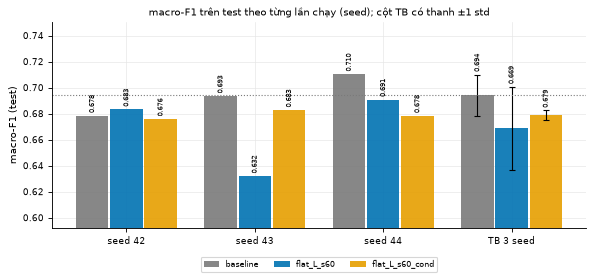

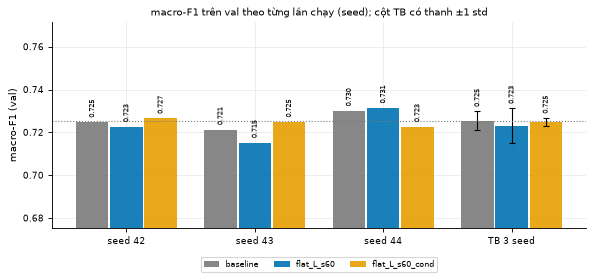

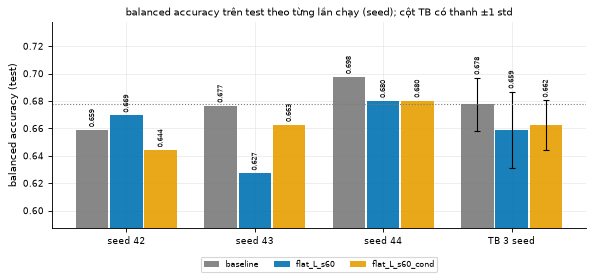

In [7]:
U.fig_seed_bars(NAMES, "test", "macro_f1", stem=f"{PROBLEM}_bars_test_macro_f1")
U.fig_seed_bars(NAMES, "val", "macro_f1", stem=f"{PROBLEM}_bars_val_macro_f1")
U.fig_seed_bars(NAMES, "test", "balanced_acc", stem=f"{PROBLEM}_bars_test_bacc");

### 5.2 Theo lớp và trên chính nhóm ảnh có vấn đề

In [8]:
print("Recall theo lớp (test): mean ± std 3 seed (Δ so với baseline; dấu theo seed)")
display(U.per_class(NAMES, "test"))
print("Trên CHÍNH nhóm ảnh có vấn đề (cờ EDA) so với phần còn lại")
display(pd.concat([U.subgroup(NAMES, P["flag"], "test"), U.subgroup(NAMES, P["flag"], "val")], ignore_index=True))

Recall theo lớp (test): mean ± std 3 seed (Δ so với baseline; dấu theo seed)


,lớp,baseline,flat_L_s60,flat_L_s60_cond
0,akiec,0.510 ± 0.162,0.429 ± 0.083 (-0.081; 1+/2-),0.490 ± 0.032 (-0.020; 1+/2-)
1,bcc,0.828 ± 0.072,0.848 ± 0.045 (+0.019; 2+/1-),0.796 ± 0.000 (-0.032; 1+/2-)
2,bkl,0.729 ± 0.051,0.661 ± 0.041 (-0.068; 0+/3-),0.694 ± 0.041 (-0.035; 1+/2-)
3,df,0.522 ± 0.075,0.493 ± 0.050 (-0.029; 2+/1-),0.522 ± 0.075 (+0.000; 1+/1-)
4,mel,0.518 ± 0.090,0.566 ± 0.123 (+0.048; 1+/2-),0.541 ± 0.096 (+0.023; 2+/1-)
5,nv,0.924 ± 0.009,0.915 ± 0.027 (-0.009; 1+/1-),0.916 ± 0.016 (-0.008; 1+/2-)
6,vasc,0.713 ± 0.080,0.701 ± 0.053 (-0.011; 1+/2-),0.678 ± 0.053 (-0.034; 0+/2-)


Trên CHÍNH nhóm ảnh có vấn đề (cờ EDA) so với phần còn lại


,cấu hình,split,n nhóm,acc nhóm baseline,acc nhóm sau xử lý,Δ acc nhóm,CI95 Δ nhóm,dấu,Δ acc còn lại,DiD,CI95 DiD,sửa (sai→đúng) từng seed,hỏng (đúng→sai) từng seed
0,flat_L_s60,test,52,0.6538,0.6795,0.0256,[-0.037; +0.090],2+/1-,-0.0114,0.0371,[-0.026; +0.102],9; 3; 11,4; 8; 7
1,flat_L_s60_cond,test,52,0.6538,0.6474,-0.0064,[-0.079; +0.070],1+/1-,-0.0096,0.0032,[-0.068; +0.081],5; 6; 6,4; 8; 6
2,flat_L_s60,val,45,0.6667,0.6593,-0.0074,[-0.103; +0.082],0+/1-,-0.0056,-0.0018,[-0.100; +0.090],3; 5; 5,3; 5; 6
3,flat_L_s60_cond,val,45,0.6667,0.6519,-0.0148,[-0.095; +0.065],0+/2-,0.0073,-0.0221,[-0.104; +0.056],3; 5; 4,3; 6; 5


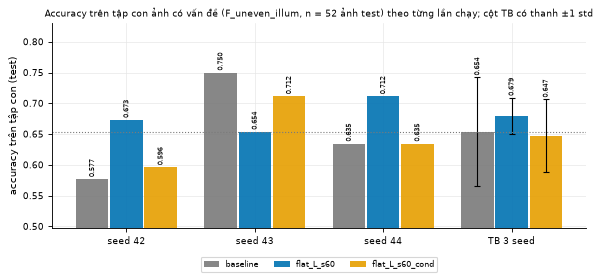

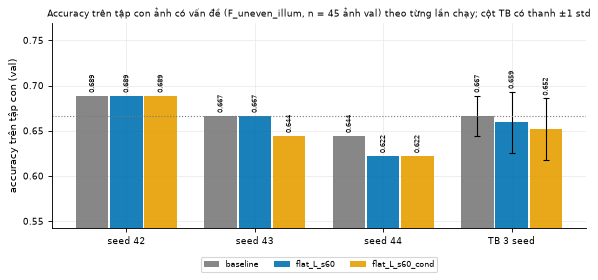

In [9]:
# Accuracy trên TẬP CON ẢNH CÓ VẤN ĐỀ, theo từng lần chạy (seed) – test và val
U.fig_subgroup_seed_bars(NAMES, P["flag"], "test", stem=f"{PROBLEM}_bars_subgroup_test_acc")
U.fig_subgroup_seed_bars(NAMES, P["flag"], "val", stem=f"{PROBLEM}_bars_subgroup_val_acc");

### 5.3 Kết luận tự động từ số liệu (theo quy tắc ở đầu notebook)

In [10]:
for split, tab in (("test", T), ("val", Tv)):
    for name in P["configs"]:
        display(Markdown("- " + U.verdict_text(tab, name, split)))

- `flat_L_s60` (test): macro-F1 0.6686 ± 0.0320, Δ = -0.0254 (CI95 -0.0503; +0.0008), dấu theo seed 1+/2- → **không khác biệt rõ**. Balanced accuracy Δ = -0.0187, 1+/2- → không khác biệt rõ.

- `flat_L_s60_cond` (test): macro-F1 0.6789 ± 0.0035, Δ = -0.0151 (CI95 -0.0450; +0.0108), dấu theo seed 0+/3- → **không khác biệt rõ**. Balanced accuracy Δ = -0.0153, 0+/3- → không khác biệt rõ.

- `flat_L_s60` (val): macro-F1 0.7231 ± 0.0081, Δ = -0.0023 (CI95 -0.0264; +0.0188), dấu theo seed 1+/2- → **không khác biệt rõ**. Balanced accuracy Δ = +0.0090, 3+/0- → không khác biệt rõ.

- `flat_L_s60_cond` (val): macro-F1 0.7247 ± 0.0019, Δ = -0.0007 (CI95 -0.0239; +0.0234), dấu theo seed 2+/1- → **không khác biệt rõ**. Balanced accuracy Δ = +0.0084, 2+/1- → không khác biệt rõ.

## 6. Kết luận và giải thích

*(Số liệu từ lượt chạy thống nhất trên NVIDIA L40S; baseline chung: `val` macro-F1 `0,7254 ± 0,0044`, `test` macro-F1 `0,6941 ± 0,0160`).*

**1. Phương pháp áp dụng:** Ước lượng trường chiếu sáng nền $B$ trên kênh $L^*$ bằng lọc Gauss lớn $\sigma = 60$ px trên vùng da ngoài tổn thương (Ch.3 + Ch.4): `flat_L_s60` (mọi ảnh) và `flat_L_s60_cond` (chỉ ảnh cờ `illum_range > 38`, không viền).

**2. Kết quả thực nghiệm (3 seed: 42, 43, 44):**
- **`flat_L_s60`:**
  - Toàn tập `val`: macro-F1 `0,7231 ± 0,0081`, Δ = `-0,0023` (CI95 `[-0,0264; +0,0188]`, `1+/2-`) → **không khác biệt rõ**.
  - Toàn tập `test`: macro-F1 `0,6686 ± 0,0320`, Δ = `-0,0254` (CI95 `[-0,0503; +0,0008]`, `1+/2-`) → **không khác biệt rõ**.
  - Trên chính nhóm ảnh bị cờ: `test` ($n = 52$) Δ acc = `+0,026` (DiD `+0,037`, CI95 `[-0,026; +0,102]`); `val` ($n = 45$) Δ acc = `-0,007`.
- **`flat_L_s60_cond`:**
  - Toàn tập `val`: macro-F1 `0,7247 ± 0,0019`, Δ = `-0,0007` (CI95 `[-0,0239; +0,0234]`, `2+/1-`) → **không khác biệt rõ**.
  - Toàn tập `test`: macro-F1 `0,6789 ± 0,0035`, Δ = `-0,0151` (CI95 `[-0,0450; +0,0108]`, `0+/3-`) → **không khác biệt rõ**.
  - Trên chính nhóm ảnh bị cờ: `test` ($n = 52$) Δ acc = `-0,006` (DiD `+0,003`, CI95 `[-0,068; +0,081]`); `val` ($n = 45$) Δ acc = `-0,015`.

**3. Giải thích cơ chế:**
- Nhóm sáng không đều có tỉ lệ lỗi baseline cao hơn kỳ vọng theo lớp ở mục 2.8.4, nhưng hiệu chỉnh nền phẳng bằng mask Otsu thô chưa đủ làm tăng macro-F1 toàn tập vượt mức dao động giữa các seed (nhóm chỉ chiếm 2,5% dữ liệu; kiểm chứng ngưỡng Tukey riêng trên `train_fit` cũng cho đúng `illum_range = 38,00`). Bản `_cond` giữ nguyên 100% ảnh bình thường nên an toàn để minh họa ở demo.

**4. Quyết định cho Pipeline (mục 2.6):** Không cấu hình nào đạt đồng thời 3 tiêu chuẩn "cải thiện rõ" trên tập `val`, nên nhánh phân loại chính giữ nguyên ảnh gốc cho ResNet-18; bộ phát hiện của vấn đề này được đưa vào **nhánh (A) Kiểm tra chất lượng (QC)** để gắn cờ cảnh báo.